In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv(
    "../data/consumption_processed.csv",
    sep=";",
    decimal=","
)

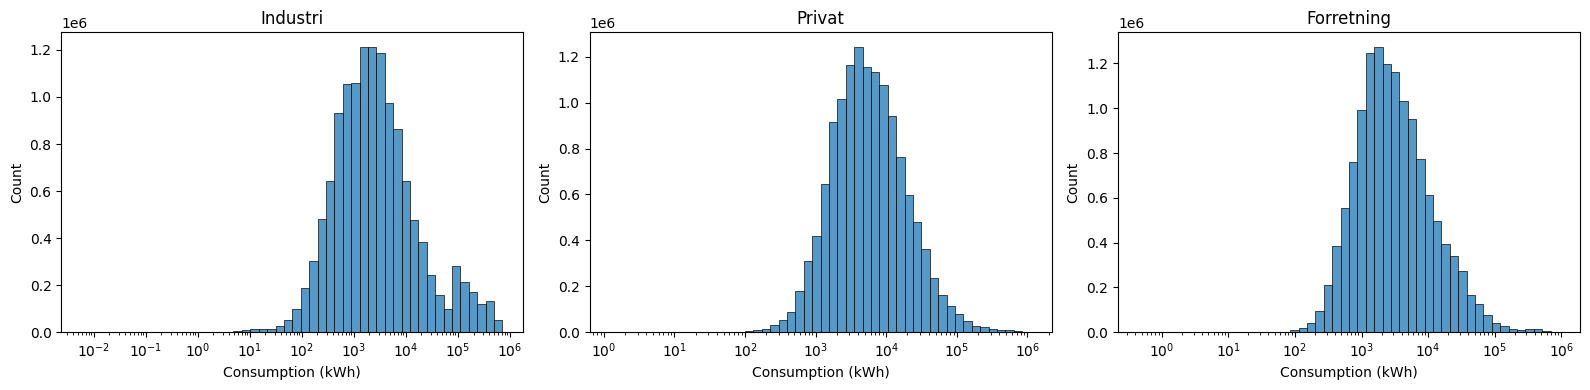

In [7]:
# Exclude non-positive values for logarithmic visualization
plot_df = df[df["VOLUM_KWH"] > 0]

groups = ["INDUSTRI", "PRIVAT", "FORRETNING"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, group in zip(axes, groups):
    subset = plot_df[
        plot_df["FORBRUKSGRUPPE"].str.upper() == group
    ]

    sns.histplot(
        data=subset,
        x="VOLUM_KWH",
        bins=50,
        log_scale=True,
        ax=ax
    )

    ax.set_title(group.title())
    ax.set_xlabel("Consumption (kWh)")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()


In [8]:
group_stats = (
    df.groupby("FORBRUKSGRUPPE")["VOLUM_KWH"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
)

display(group_stats.round(2))

,count,mean,median,std,min,max
FORBRUKSGRUPPE,,,,,,
Forretning,13317242,8507.83,2680.89,26822.89,-984.40,923674.44
Industri,13317234,20105.72,2204.84,67062.69,-2137.58,716742.48
Privat,13317242,13111.25,5281.04,33617.94,-476.95,1110606.30


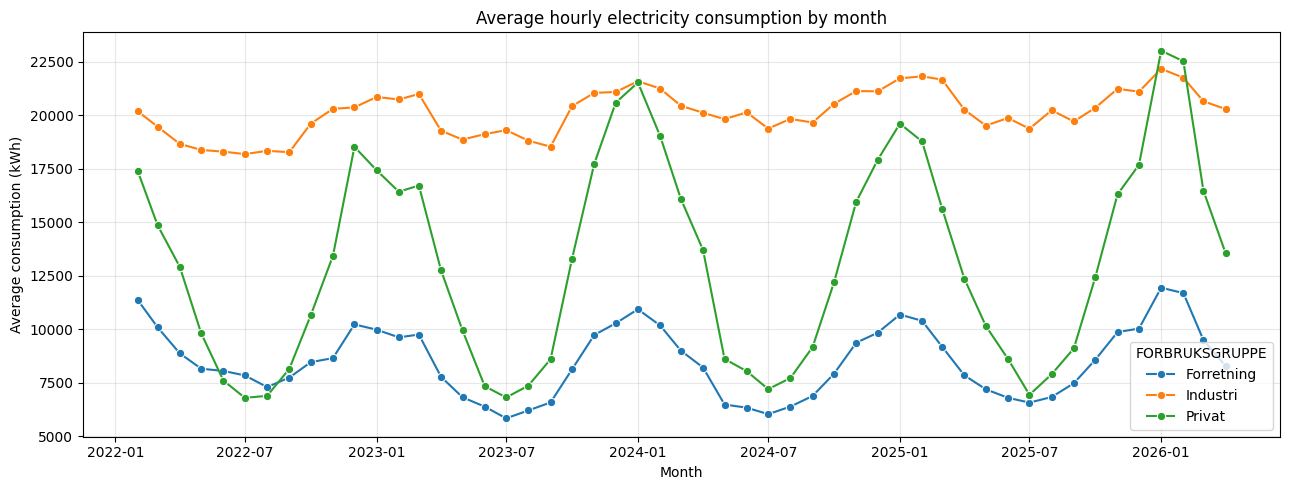

In [9]:
# Monthly average hourly consumption by group
monthly = (
    df.groupby(
        ["YEAR", "MONTH", "FORBRUKSGRUPPE"]
    )["VOLUM_KWH"]
    .mean()
    .reset_index()
)

# Create date column
monthly["DATE"] = pd.to_datetime(
    monthly[["YEAR", "MONTH"]].assign(DAY=1)
)

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly,
    x="DATE",
    y="VOLUM_KWH",
    hue="FORBRUKSGRUPPE",
    marker="o"
)

plt.title("Average hourly electricity consumption by month")
plt.xlabel("Month")
plt.ylabel("Average consumption (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


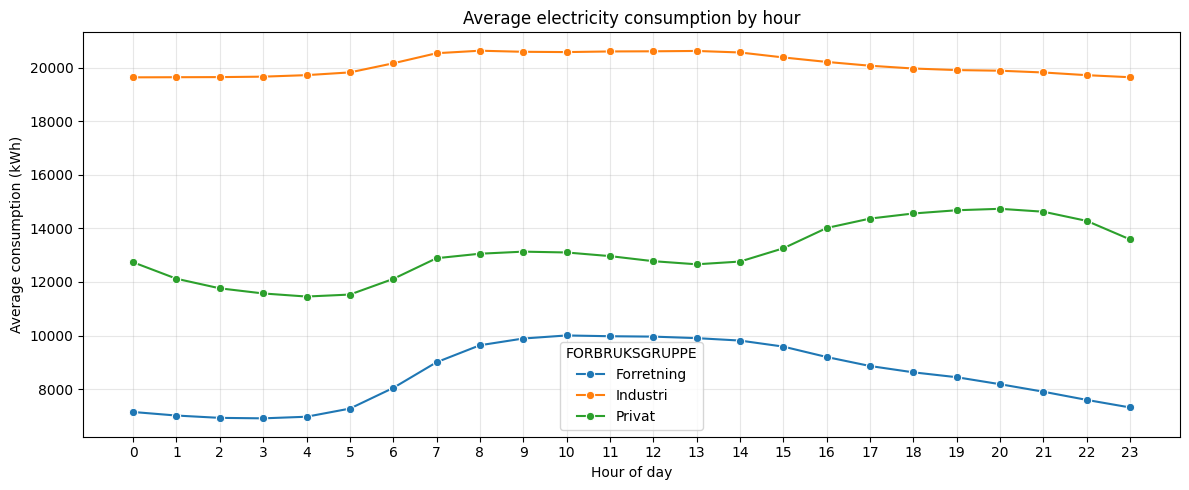

In [10]:
hourly = (
    df.groupby(["HOUR", "FORBRUKSGRUPPE"])["VOLUM_KWH"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly,
    x="HOUR",
    y="VOLUM_KWH",
    hue="FORBRUKSGRUPPE",
    marker="o"
)

plt.title("Average electricity consumption by hour")
plt.xlabel("Hour of day")
plt.ylabel("Average consumption (kWh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

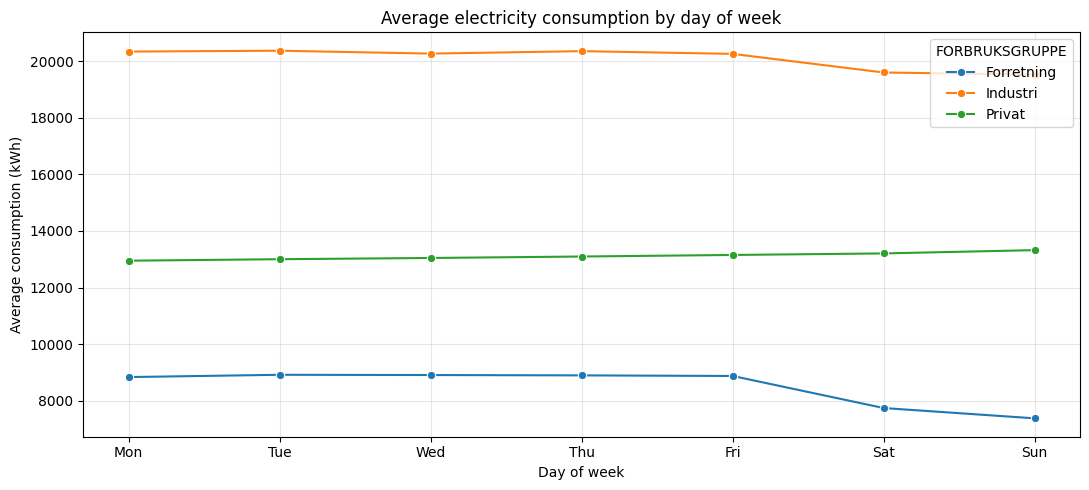

In [11]:
weekday = (
    df.groupby(["DAY_OF_WEEK", "FORBRUKSGRUPPE"])["VOLUM_KWH"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=weekday,
    x="DAY_OF_WEEK",
    y="VOLUM_KWH",
    hue="FORBRUKSGRUPPE",
    marker="o"
)

plt.title("Average electricity consumption by day of week")
plt.xlabel("Day of week")
plt.ylabel("Average consumption (kWh)")
plt.xticks(
    range(7),
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### EDA: Electricity Consumption Patterns

**Distribution of consumption**
- Electricity consumption is strongly right-skewed across all three consumption groups.
- Industry has the highest mean consumption and largest variance, while private consumption has the highest median.
- The large differences between mean and median indicate that high-consumption observations strongly influence the averages.

**Temporal patterns**
- **Monthly:** Strong seasonal variation, especially for private consumption, with higher consumption during winter and lower consumption during summer.
- **Hourly:** Business consumption increases during working hours, while private consumption peaks in the evening. Industrial consumption remains relatively stable.
- **Weekly:** Business consumption drops noticeably during weekends. Industrial consumption decreases slightly, while private consumption increases slightly.

**Implications for modelling**
- `MONTH`, `HOUR`, `DAY_OF_WEEK` and `FORBRUKSGRUPPE` are potentially important predictors.
- Temporal patterns differ between consumption groups, suggesting possible interaction effects.
- Nonlinear models may capture these relationships better than simple linear regression.
- Differences in consumption scale and variability should be considered when evaluating model performance.

In [ ]:
df["KWH_PER_PUNKT"] = np.where(
    df["ANTALL_MÅLEPUNKT"] > 0,
    df["VOLUM_KWH"] / df["ANTALL_MÅLEPUNKT"],
    np.nan
)

df["KWH_PER_PUNKT"].describe()

count    3.995172e+07
mean     3.410281e+01
std      2.413377e+02
min     -1.826993e+01
25%      1.994321e+00
50%      5.215506e+00
75%      1.096896e+01
max      6.930080e+03
Name: KWH_PER_PUNKT, dtype: float64

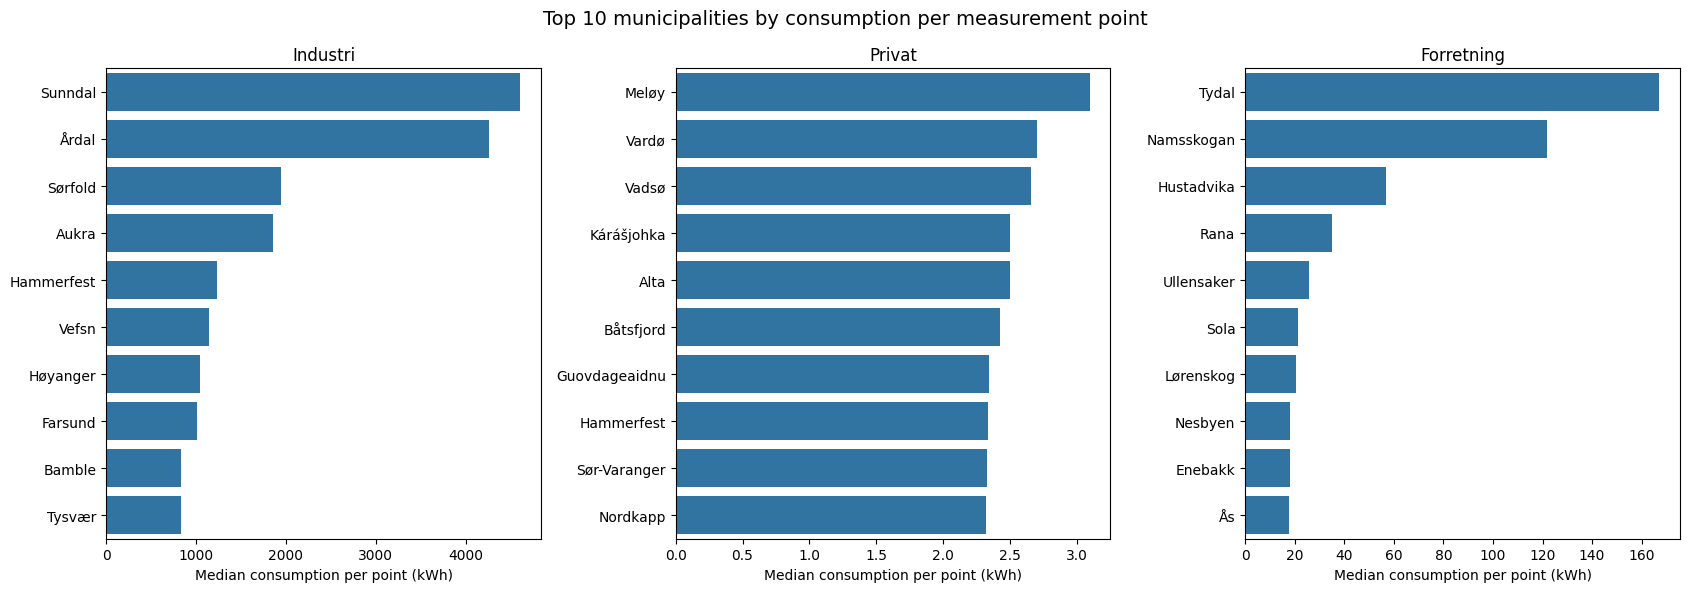

In [15]:
# Median consumption per measurement point by municipality and group
municipality_stats = (
    df.groupby(["KOMMUNE", "FORBRUKSGRUPPE"])["KWH_PER_PUNKT"]
    .median()
    .reset_index()
)

# Select top 10 municipalities within each consumption group
top10 = (
    municipality_stats
    .sort_values("KWH_PER_PUNKT", ascending=False)
    .groupby("FORBRUKSGRUPPE")
    .head(10)
)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

groups = ["Industri", "Privat", "Forretning"]

for ax, group in zip(axes, groups):
    subset = (
        top10[top10["FORBRUKSGRUPPE"] == group]
        .sort_values("KWH_PER_PUNKT", ascending=False)
    )

    sns.barplot(
        data=subset,
        x="KWH_PER_PUNKT",
        y="KOMMUNE",
        ax=ax
    )

    ax.set_title(group)
    ax.set_xlabel("Median consumption per point (kWh)")
    ax.set_ylabel("")

plt.suptitle(
    "Top 10 municipalities by consumption per measurement point",
    fontsize=14
)
plt.tight_layout()
plt.show()

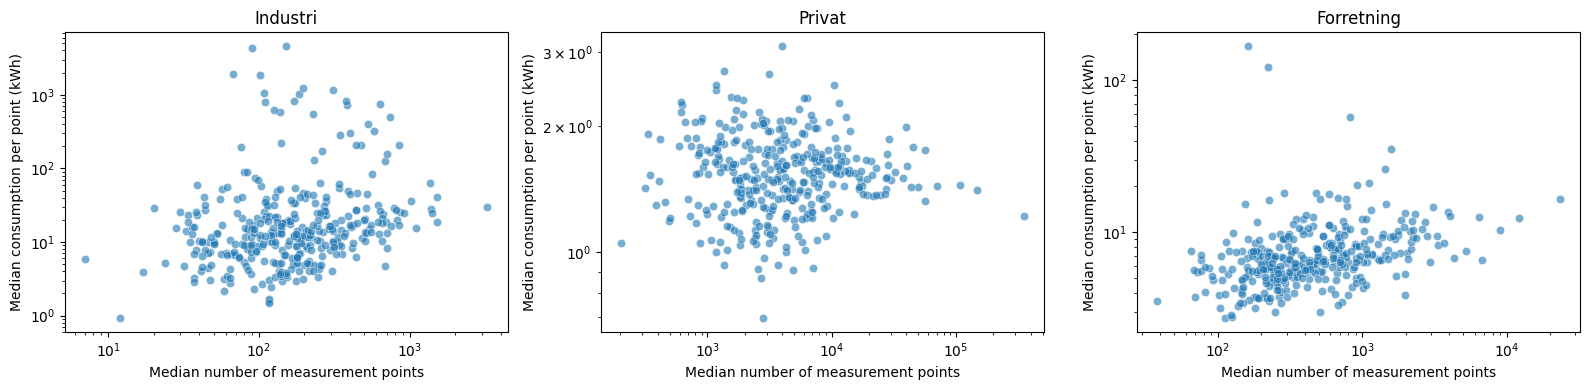

In [16]:
municipality_points = (
    df.groupby(["KOMMUNE", "FORBRUKSGRUPPE"])
    .agg(
        median_kwh_per_point=("KWH_PER_PUNKT", "median"),
        median_measurement_points=("ANTALL_MÅLEPUNKT", "median")
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, group in zip(axes, ["Industri", "Privat", "Forretning"]):
    subset = municipality_points[
        municipality_points["FORBRUKSGRUPPE"] == group
    ]

    sns.scatterplot(
        data=subset,
        x="median_measurement_points",
        y="median_kwh_per_point",
        ax=ax,
        alpha=0.6
    )

    ax.set_title(group)
    ax.set_xlabel("Median number of measurement points")
    ax.set_ylabel("Median consumption per point (kWh)")
    ax.set_xscale("log")
    ax.set_yscale("log")

plt.tight_layout()
plt.show()

In [17]:
municipalities = [
    "Oslo", "Bergen", "Stavanger", "Trondheim",
    "Tromsø", "Bodø", "Kristiansand",
    "Drammen", "Ålesund", "Alta",
    "Sunndal", "Årdal"
]

coverage = (
    df[df["KOMMUNE"].isin(municipalities)]
    .groupby(["KOMMUNE", "FORBRUKSGRUPPE"])
    .agg(
        observations=("VOLUM_KWH", "size"),
        first_date=("STARTTID", "min"),
        last_date=("STARTTID", "max"),
        median_points=("ANTALL_MÅLEPUNKT", "median")
    )
)

display(coverage)

observations                 first_date  \
KOMMUNE      FORBRUKSGRUPPE                                            
Alta         Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Bergen       Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Bodø         Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Drammen      Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Kristiansand Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Oslo         Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Stavanger    Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Sunndal      Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Tromsø       Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Trondheim    Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Ålesund      Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   
Årdal        Forretning             37199  2022-02-01 00:00:00+01:00   
             Industri               37199  2022-02-01 00:00:00+01:00   
             Privat                 37199  2022-02-01 00:00:00+01:00   

                                             last_date  median_points  
KOMMUNE      FORBRUKSGRUPPE                                            
Alta         Forretning      2026-04-30 23:00:00+02:00         1145.0  
             Industri        2026-04-30 23:00:00+02:00          420.0  
             Privat          2026-04-30 23:00:00+02:00        10493.0  
Bergen       Forretning      2026-04-30 23:00:00+02:00        12188.0  
             Industri        2026-04-30 23:00:00+02:00         1517.0  
             Privat          2026-04-30 23:00:00+02:00       148991.0  
Bodø         Forretning      2026-04-30 23:00:00+02:00         2741.0  
             Industri        2026-04-30 23:00:00+02:00          532.0  
             Privat          2026-04-30 23:00:00+02:00        28743.0  
Drammen      Forretning      2026-04-30 23:00:00+02:00         5237.0  
             Industri        2026-04-30 23:00:00+02:00          787.0  
             Privat          2026-04-30 23:00:00+02:00        49544.0  
Kristiansand Forretning      2026-04-30 23:00:00+02:00         6808.0  
             Industri        2026-04-30 23:00:00+02:00         1355.0  
             Privat          2026-04-30 23:00:00+02:00        56914.0  
Oslo         Forretning      2026-04-30 23:00:00+02:00        23386.